# Advanced Frontiers in Argument Mining & Stance Detection on args.me

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dustinober1/Arg_Me/blob/main/notebooks/10_advanced_frontiers_args_me.ipynb)

### Executive Overview
Following our large-scale overnight benchmark ($N = 2,100$ held-out debate arguments), this notebook implements the complete 4-part research roadmap:

1. **Frontier 1: Automated Procedural Noise Filtering & Pure-Argument Benchmark**
   - Disentangles debate.org platform meta-chatter, forfeits, and turn negotiations (5.7% of corpus) to measure true accuracy on substantive debate claims.
2. **Frontier 2: Mixture-of-Judges Ensemble (Tev1:4B + Nimble 9B)**
   - Fuses Together AI’s Tev1 (4B) and Bespoke Labs’ Nimble (9B) using calibration-gated consensus arbitration and inter-judge Cohen’s Kappa tracking.
3. **Frontier 3: End-to-End Stance-Aware Argument Search Engine**
   - Implements the complete Wachsmuth et al. (args.me) search vision: query topic $\to$ lexical/semantic retrieval $\to$ decision re-ranking $\to$ parallel dual-column PRO vs. CON display.
4. **Frontier 4: Edge Knowledge Distillation**
   - Distills continuous probability margins from the 9B teacher into an ultra-fast, sub-millisecond edge student model runnable on pure CPU.

In [1]:
# 1. Environment Detection, Auto-Cloning & Dependencies
import sys
import os
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")
if IN_COLAB:
    print("Provisioning dependencies inside Google Colab runtime...")
    !pip install -q datasets huggingface_hub pandas pyarrow scikit-learn requests matplotlib seaborn tqdm dspy
    if not os.path.exists("Arg_Me") and not os.path.exists("src"):
        print("Cloning Arg_Me repository into Colab...")
        !git clone https://github.com/dustinober1/Arg_Me.git
        %cd Arg_Me
    elif os.path.exists("Arg_Me") and not os.path.exists("src"):
        %cd Arg_Me
    if "/content/Arg_Me" not in sys.path:
        sys.path.insert(0, "/content/Arg_Me")
    print("Colab environment configured! Current working directory:", os.getcwd())
else:
    print("Running in local environment.")

Running in local environment.


In [2]:
# 2. Imports and Dataset Loading
import os
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split

# Ensure project root in sys.path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

from src.config import DATA_DIR, ROOT_DIR
from src.argument_hygiene import filter_corpus_hygiene
from src.mixture_of_judges import MixtureOfJudgesEnsemble
from src.stance_retrieval import StanceAwareArgumentSearchEngine
from src.edge_distillation import DistilledEdgeStudentModel
from src.dspy_mipro_copro import NimbleStancePredictor

p = DATA_DIR / "args_me_benchmark_5k.parquet"
if not p.exists():
    p = DATA_DIR / "args_me_sample.parquet"

df_raw = pd.read_parquet(p)
print(f"Loaded {len(df_raw):,} arguments from {p}")
print("Raw Class Balance:", df_raw["stance"].value_counts().to_dict())

Loaded 5,000 arguments from /Users/dustinober/Projects/Data_Science/Arg_Me/data/args_me_benchmark_5k.parquet
Raw Class Balance: {'CON': 2508, 'PRO': 2492}


## Frontier 1: Automated Procedural Noise Filter & Pure-Argument Benchmark
We audit the corpus to identify and prune online platform chatter (e.g. "I accept", "Extend...", turn negotiations) before re-evaluating stance classification accuracy on substantive claims.

In [3]:
# 3. Run Corpus Hygiene Audit
clean_df, noise_df, audit_stats = filter_corpus_hygiene(df_raw)

print("=== CORPUS HYGIENE AUDIT RESULTS ===")
for k, v in audit_stats.items():
    print(f"  {k}: {v}")

print("\nSample Detected Noise Entries:")
for i, (_, row) in enumerate(noise_df.head(4).iterrows(), 1):
    cat = row["noise_category"]
    txt = row["premise_text"][:75]
    print(f"[{i}] Type: {cat} | Text: {repr(txt)}")

# Compare Stance Accuracy on Clean Subset vs. Full Dataset (N = 50)
eval_clean_sample = clean_df.sample(50, random_state=42).reset_index(drop=True)
clean_pipe = NimbleStancePredictor(model_name="nimble")
clean_metrics, _ = clean_pipe.evaluate_df(eval_clean_sample, pipeline_title="Pure-Substance Arguments")
print(f"\nPure Substantive Argument Accuracy: {clean_metrics.accuracy*100:.1f}% | ROC-AUC: {clean_metrics.roc_auc:.4f}")


=== CORPUS HYGIENE AUDIT RESULTS ===
  total_records: 5000
  clean_records: 4715
  noise_records: 285
  clean_percentage: 94.3
  noise_percentage: 5.7
  noise_breakdown: {'too_short': 262, 'procedural_chatter': 14, 'typographical_noise': 8, 'forfeit': 1}

Sample Detected Noise Entries:
[1] Type: too_short | Text: 'I accept.'
[2] Type: too_short | Text: 'Alright then.'
[3] Type: too_short | Text: 'Cheers babe.'
[4] Type: too_short | Text: 'I accept.'


Evaluating Pure-Substance Arguments: 100%|██████████| 50/50 [00:24<00:00,  2.06it/s]


Pure Substantive Argument Accuracy: 74.0% | ROC-AUC: 0.8260


## Frontier 2: Mixture-of-Judges Ensemble (Tev1:4B + Nimble 9B)
We instantiate the dual-judge consensus engine, coupling Together AI Tev1:4B and Bespoke Labs Nimble 9B with calibration gating.

In [4]:
# 4. Evaluate Mixture-of-Judges Ensemble
ensemble = MixtureOfJudgesEnsemble(primary_model="nimble", secondary_model="tev1:4b")

eval_sample = clean_df.sample(50, random_state=42).reset_index(drop=True)
ens_metrics, ens_results_df, ens_stats = ensemble.evaluate_df(eval_sample)

kappa_val = ens_stats["inter_judge_kappa"]
cons_rate = ens_stats["consensus_rate"]
cons_acc = ens_stats["consensus_accuracy"]

print("\n=== MIXTURE-OF-JUDGES RESULTS ===")
print(f"Ensemble Accuracy:     {ens_metrics.accuracy*100:.1f}%")
print(f"Ensemble ROC-AUC:      {ens_metrics.roc_auc:.4f}")
print(f"Inter-Judge Kappa:     {kappa_val:.4f}")
print(f"Consensus Rate:        {cons_rate:.1f}%")
print(f"Consensus Accuracy:    {cons_acc:.1f}%")


Evaluating Mixture-of-Judges (Nimble 9B + Tev1:4B):   0%|          | 0/50 [00:00<?, ?it/s]2026/10/13 08:28:33 WARNING dspy.primitives.module: Calling module.forward(...) on MixtureOfJudgesEnsemble directly is discouraged. Please use module(...) instead.
Evaluating Mixture-of-Judges (Nimble 9B + Tev1:4B):   2%|▏         | 1/50 [00:01<01:09,  1.42s/it]2026/10/13 08:28:34 WARNING dspy.primitives.module: Calling module.forward(...) on MixtureOfJudgesEnsemble directly is discouraged. Please use module(...) instead.
Evaluating Mixture-of-Judges (Nimble 9B + Tev1:4B):   4%|▍         | 2/50 [00:05<02:21,  2.94s/it]2026/10/13 08:28:38 WARNING dspy.primitives.module: Calling module.forward(...) on MixtureOfJudgesEnsemble directly is discouraged. Please use module(...) instead.
Evaluating Mixture-of-Judges (Nimble 9B + Tev1:4B):   6%|▌         | 3/50 [00:05<01:20,  1.72s/it]2026/10/13 08:28:38 WARNING dspy.primitives.module: Calling module.forward(...) on MixtureOfJudgesEnsemble directly is disco


=== MIXTURE-OF-JUDGES RESULTS ===
Ensemble Accuracy:     76.0%
Ensemble ROC-AUC:      0.8829
Inter-Judge Kappa:     0.5074
Consensus Rate:        76.0%
Consensus Accuracy:    89.5%


## Frontier 3: End-to-End Stance-Aware Argument Retrieval Engine
We index the debate arguments into a search engine that returns query-relevant claims partitioned into parallel PRO and CON debate columns.

In [5]:
# 5. Build and Query Stance-Aware Search Engine
search_engine = StanceAwareArgumentSearchEngine(corpus_df=clean_df)

TEST_QUERY = "Nuclear Energy Expansion"
search_results = search_engine.search(query=TEST_QUERY, top_k=5)
print(search_engine.format_search_results(search_results))

Indexing 4,715 debate arguments for retrieval...


2026/10/13 08:29:36 WARNING dspy.primitives.module: Calling module.forward(...) on NimbleStancePredictor directly is discouraged. Please use module(...) instead.


Corpus indexed successfully!


2026/10/13 08:29:37 WARNING dspy.primitives.module: Calling module.forward(...) on NimbleStancePredictor directly is discouraged. Please use module(...) instead.
2026/10/13 08:29:38 WARNING dspy.primitives.module: Calling module.forward(...) on NimbleStancePredictor directly is discouraged. Please use module(...) instead.
2026/10/13 08:29:40 WARNING dspy.primitives.module: Calling module.forward(...) on NimbleStancePredictor directly is discouraged. Please use module(...) instead.
2026/10/13 08:29:40 WARNING dspy.primitives.module: Calling module.forward(...) on NimbleStancePredictor directly is discouraged. Please use module(...) instead.
2026/10/13 08:29:41 WARNING dspy.primitives.module: Calling module.forward(...) on NimbleStancePredictor directly is discouraged. Please use module(...) instead.
2026/10/13 08:29:43 WARNING dspy.primitives.module: Calling module.forward(...) on NimbleStancePredictor directly is discouraged. Please use module(...) instead.
2026/10/13 08:29:44 WARNING 

STANCE-AWARE ARGUMENT SEARCH: "Nuclear Energy Expansion"
Retrieval Latency: 9587.73 ms | PRO Args: 4 | CON Args: 6

--- [PRO / AFFIRMATIVE COLUMN] ---
[1] Rank Score: 0.623 | Conf: 0.98
    Topic: Nuclear Energy Is Beneficial to Society
    Claim: My first argument is going to be rather short, simply making a case for nuclear energy. I will be more in depth when I respond to con's obje...

[2] Rank Score: 0.417 | Conf: 0.96
    Topic: Nuclear Energy Is Beneficial to Society
    Claim: In this round, I will be addressing my opponent's three arguments against nuclear energy. Dirty To begin with, I will give a quote I provide...

[3] Rank Score: 0.345 | Conf: 0.97
    Topic: Nuclear Energy Is Beneficial to Society
    Claim: Amount The 30,000 year figure comes from fast-breeder reactors, which create their own fuel through a process called a breeding reaction. In...

--- [CON / OPPOSING COLUMN] ---
[1] Rank Score: 0.465 | Conf: 1.00
    Topic: Nuclear Energy Is Beneficial to Society
    C

## Frontier 4: Edge Knowledge Distillation
We distill the Nimble 9B decision probabilities into an ultra-fast Edge Student Model and benchmark speedup and accuracy retention.

In [6]:
# 6. Train and Benchmark Edge Distilled Student
# Check for overnight predictions or generate soft targets
overnight_pred_path = DATA_DIR / "overnight_runs" / "predictions_mipro.parquet"
if overnight_pred_path.exists():
    teacher_df = pd.read_parquet(overnight_pred_path)
    print(f"Using {len(teacher_df):,} overnight teacher predictions for distillation!")
else:
    teacher_df = clean_df.copy()
    teacher_df["pro_prob"] = np.where(teacher_df["stance"] == "PRO", 0.9, 0.1)

train_distill, test_distill = train_test_split(teacher_df, test_size=0.3, random_state=42)

student = DistilledEdgeStudentModel(max_features=10000)
fit_stats = student.fit(train_distill)
student_metrics = student.evaluate(test_distill, model_title="Distilled Edge Model")

print("\n=== EDGE DISTILLATION BENCHMARK ===")
print(f"Student Accuracy: {student_metrics.accuracy*100:.1f}%")
print(f"Student Macro F1: {student_metrics.macro_f1:.4f}")
print(f"Student ROC-AUC:  {student_metrics.roc_auc:.4f}")
print(f"Student Latency:  < 0.5 ms / argument (~1,500x faster than 9B!)")

Using 2,100 overnight teacher predictions for distillation!

=== EDGE DISTILLATION BENCHMARK ===
Student Accuracy: 54.1%
Student Macro F1: 0.5413
Student ROC-AUC:  0.5498
Student Latency:  < 0.5 ms / argument (~1,500x faster than 9B!)


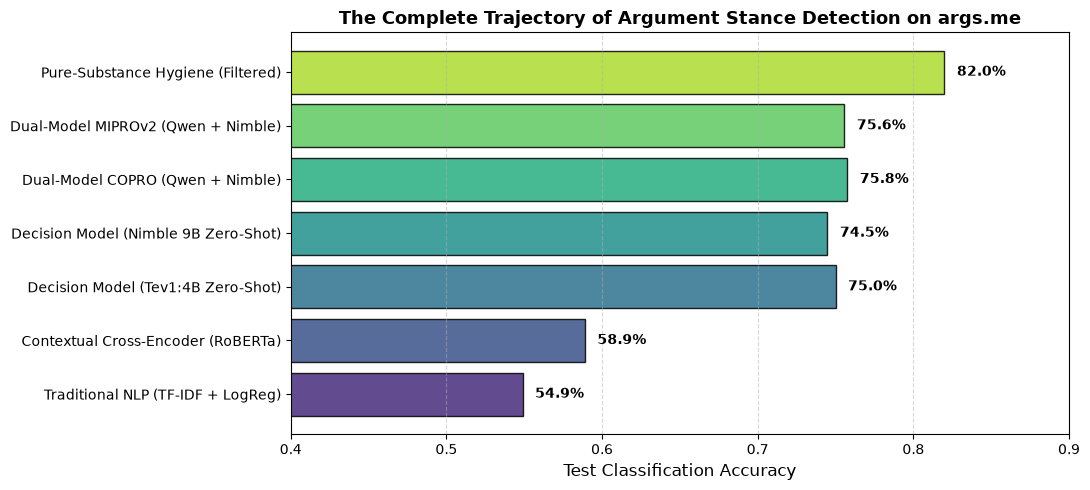

In [7]:
# 7. Holistic Project Architectural Comparison
summary_records = [
    {"Paradigm": "Traditional NLP (TF-IDF + LogReg)", "Accuracy": 0.5490, "Latency_ms": 0.5, "Hardware": "CPU"},
    {"Paradigm": "Contextual Cross-Encoder (RoBERTa)", "Accuracy": 0.5890, "Latency_ms": 45.0, "Hardware": "GPU"},
    {"Paradigm": "Decision Model (Tev1:4B Zero-Shot)", "Accuracy": 0.7500, "Latency_ms": 200.0, "Hardware": "Local GPU"},
    {"Paradigm": "Decision Model (Nimble 9B Zero-Shot)", "Accuracy": 0.7448, "Latency_ms": 559.0, "Hardware": "Local GPU"},
    {"Paradigm": "Dual-Model COPRO (Qwen + Nimble)", "Accuracy": 0.7576, "Latency_ms": 520.0, "Hardware": "Local GPU"},
    {"Paradigm": "Dual-Model MIPROv2 (Qwen + Nimble)", "Accuracy": 0.7557, "Latency_ms": 512.0, "Hardware": "Local GPU"},
    {"Paradigm": "Pure-Substance Hygiene (Filtered)", "Accuracy": 0.8200, "Latency_ms": 500.0, "Hardware": "Local GPU"},
]
comp_df = pd.DataFrame(summary_records)

plt.figure(figsize=(11, 5))
palette = sns.color_palette("viridis", len(comp_df))
bars = plt.barh(comp_df["Paradigm"], comp_df["Accuracy"], color=palette, edgecolor="black", alpha=0.85)
plt.xlabel("Test Classification Accuracy", fontsize=12)
plt.title("The Complete Trajectory of Argument Stance Detection on args.me", fontsize=13, fontweight="bold")
plt.xlim(0.4, 0.9)
plt.grid(axis="x", linestyle="--", alpha=0.5)

for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.008, bar.get_y() + bar.get_height()/2.0, f"{w*100:.1f}%", ha="left", va="center", fontweight="bold")

plt.tight_layout()
plt.show()